In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

def housing_data_reader(filename='life.csv'):
    data = pd.read_csv(filename)
    X = data.drop(['Life expectancy '],axis = 1)
    y = data['Life expectancy ']
    return X, y

In [2]:
from sklearn.model_selection import train_test_split
import lightgbm as lgb
from sklearn.metrics import r2_score
# define the characteristic function
def classification_kpi(G,S):
    """_summary_

    Args:
        G (nx.Graph): _description_
        S (list): list of nodes (list of columns)
    """
    cols = list(S)
    if len(cols) == 0:
        return 0
    else:
        X_train, X_test, y_train, y_test = train_test_split(X[cols], y, test_size=0.2, random_state=42)
        lgb_model = lgb.LGBMRegressor(verbose=-1)
        lgb_model.fit(X_train,y_train)
        lgb_pred = lgb_model.predict(X_test)
        r2 = r2_score(y_test, lgb_pred)
        return r2

In [3]:
import networkx as nx
import shapG.shapley as shapley
import shapG.plot as shapGplot
from shapG.utils import corr_generator, create_minimal_edge_graph
import time

In [4]:
s = time.time()

In [5]:
# explain the model
X, y = housing_data_reader('life.csv')
W = corr_generator(X)
A, W_new = create_minimal_edge_graph(W, version='v3')
G = nx.Graph(A)
shapley_value = shapley.shapG(G, m=3, f=classification_kpi, approximate_by_ratio=False)

100%|███████████████████████████████████████████| 21/21 [03:51<00:00, 11.03s/it]


In [6]:
e = time.time()
e-s

232.07765293121338

In [7]:
sorted_data = sorted(shapley_value.items(), key=lambda x: x[1])

sorted_data

[('Year', -0.005311337075222161),
 ('Population', 0.15074266369291253),
 ('Measles ', 0.15897971206632672),
 ('Hepatitis B', 0.22779807095593682),
 ('Status', 0.26483285441485055),
 ('Total expenditure', 0.27326179010847107),
 ('Alcohol', 0.46170765631632793),
 ('percentage expenditure', 0.4886102116066829),
 ('Country', 0.6782891490943479),
 ('GDP', 0.747566115134439),
 (' thinness 5-9 years', 0.894322596548364),
 ('Polio', 0.9261086895847765),
 ('Diphtheria ', 0.9571127727361846),
 (' thinness  1-19 years', 0.9752023352484256),
 (' BMI ', 1.0617227091192845),
 ('under-five deaths ', 1.1202939420969016),
 ('infant deaths', 1.1578828195746813),
 ('Schooling', 1.3399602931018448),
 (' HIV/AIDS', 1.4615368534761428),
 ('Income composition of resources', 1.7336655051966565),
 ('Adult Mortality', 1.9081840844069389)]

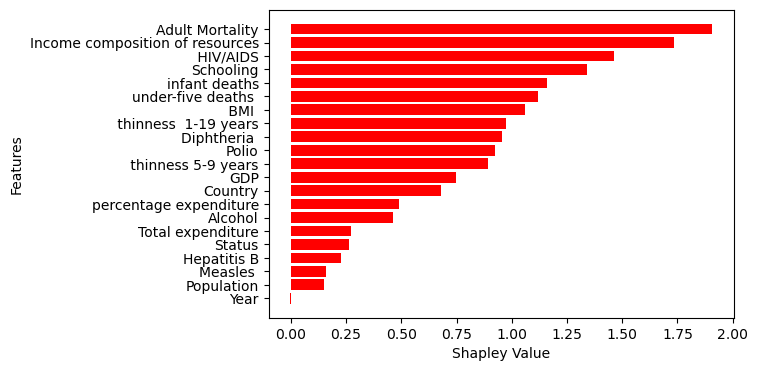

In [8]:
import matplotlib.pyplot as plt

# 提取特征名称和权重（按权重从大到小排序）
data = [
    ('Year', -0.005311337075222161),
    ('Population', 0.15074266369291253),
    ('Measles ', 0.15897971206632672),
    ('Hepatitis B', 0.22779807095593682),
    ('Status', 0.26483285441485055),
    ('Total expenditure', 0.27326179010847107),
    ('Alcohol', 0.46170765631632793),
    ('percentage expenditure', 0.4886102116066829),
    ('Country', 0.6782891490943479),
    ('GDP', 0.747566115134439),
    (' thinness 5-9 years', 0.894322596548364),
    ('Polio', 0.9261086895847765),
    ('Diphtheria ', 0.9571127727361846),
    (' thinness  1-19 years', 0.9752023352484256),
    (' BMI ', 1.0617227091192845),
    ('under-five deaths ', 1.1202939420969016),
    ('infant deaths', 1.1578828195746813),
    ('Schooling', 1.3399602931018448),
    (' HIV/AIDS', 1.4615368534761428),
    ('Income composition of resources', 1.7336655051966565),
    ('Adult Mortality', 1.9081840844069389)
]

labels, values = zip(*data)

plt.figure(figsize=(6,4))
# plt.figure(figsize=(4, 4))

# 创建一个渐变颜色列表
# colors = plt.cm.Blues(np.linspace(0, 1, len(values)))

# 使用Matplotlib的bar()函数绘制带有渐变颜色的条形图
plt.barh(labels, values, color='r')

plt.xlabel('Shapley Value')
plt.ylabel('Features')
# plt.title('Shapley Value for Each Feature in Housing Price Dataset Based on LightGBM Model')

# 保存图像
# plt.savefig('housing_importance.png', dpi=300)
plt.savefig('shapG_life_lgb.eps', format='eps', dpi=300)

plt.show()


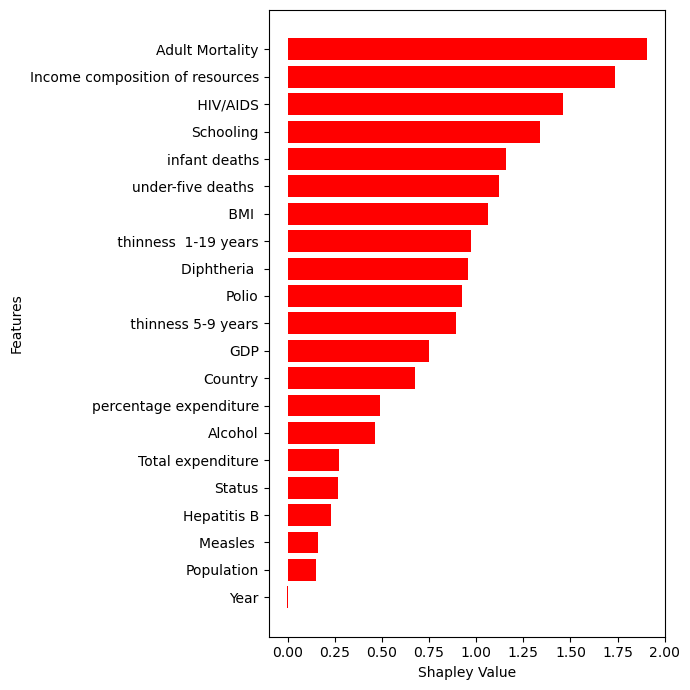

In [18]:
import matplotlib.pyplot as plt

# 提取特征名称和权重（按权重从大到小排序）
data = [
    ('Year', -0.005311337075222161),
    ('Population', 0.15074266369291253),
    ('Measles ', 0.15897971206632672),
    ('Hepatitis B', 0.22779807095593682),
    ('Status', 0.26483285441485055),
    ('Total expenditure', 0.27326179010847107),
    ('Alcohol', 0.46170765631632793),
    ('percentage expenditure', 0.4886102116066829),
    ('Country', 0.6782891490943479),
    ('GDP', 0.747566115134439),
    (' thinness 5-9 years', 0.894322596548364),
    ('Polio', 0.9261086895847765),
    ('Diphtheria ', 0.9571127727361846),
    (' thinness  1-19 years', 0.9752023352484256),
    (' BMI ', 1.0617227091192845),
    ('under-five deaths ', 1.1202939420969016),
    ('infant deaths', 1.1578828195746813),
    ('Schooling', 1.3399602931018448),
    (' HIV/AIDS', 1.4615368534761428),
    ('Income composition of resources', 1.7336655051966565),
    ('Adult Mortality', 1.9081840844069389)
]

labels, values = zip(*data)

plt.figure(figsize=(7, 7))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(labels, values, color='r')

plt.xlabel('Shapley Value')
plt.ylabel('Features')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()

# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('shapG_life_lgb.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()


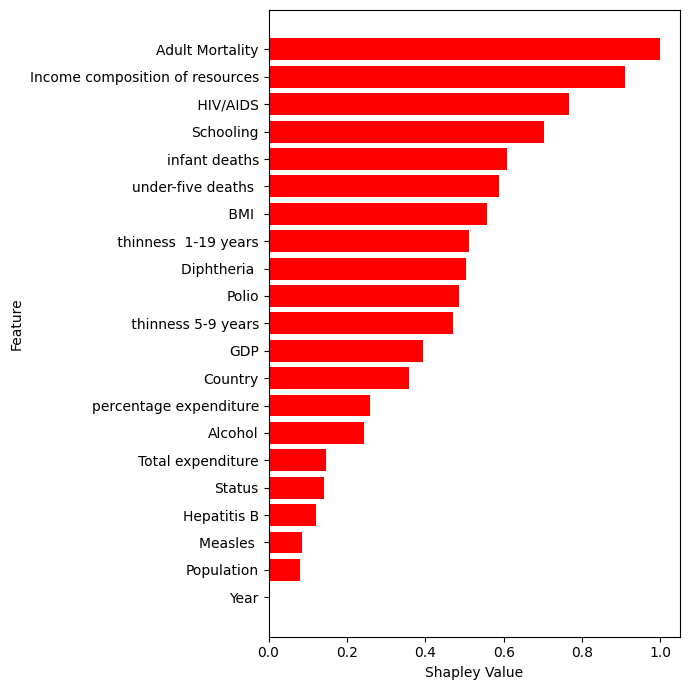

In [1]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# 提取特征名称和权重（按权重从大到小排序）
data = [
    ('Year', -0.005311337075222161),
    ('Population', 0.15074266369291253),
    ('Measles ', 0.15897971206632672),
    ('Hepatitis B', 0.22779807095593682),
    ('Status', 0.26483285441485055),
    ('Total expenditure', 0.27326179010847107),
    ('Alcohol', 0.46170765631632793),
    ('percentage expenditure', 0.4886102116066829),
    ('Country', 0.6782891490943479),
    ('GDP', 0.747566115134439),
    (' thinness 5-9 years', 0.894322596548364),
    ('Polio', 0.9261086895847765),
    ('Diphtheria ', 0.9571127727361846),
    (' thinness  1-19 years', 0.9752023352484256),
    (' BMI ', 1.0617227091192845),
    ('under-five deaths ', 1.1202939420969016),
    ('infant deaths', 1.1578828195746813),
    ('Schooling', 1.3399602931018448),
    (' HIV/AIDS', 1.4615368534761428),
    ('Income composition of resources', 1.7336655051966565),
    ('Adult Mortality', 1.9081840844069389)
]

# 分离特征名称和权重
labels, values = zip(*data)

# 将权重转换为numpy数组
values = np.array(values).reshape(-1, 1)

# 使用MinMaxScaler进行归一化
scaler = MinMaxScaler()
normalized_values = scaler.fit_transform(values).flatten()

# 绘制条形图
plt.figure(figsize=(7, 7))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(labels, normalized_values, color='r')

plt.xlabel('Shapley Value')
plt.ylabel('Feature')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()

# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('shapG_life_lgb_normalized.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()